In [4]:
import pandas as pd

ratings = pd.read_csv("../data/ml-latest-small/ratings.csv")
movies = pd.read_csv("../data/ml-latest-small/movies.csv")

print("Avaliações:", ratings.shape)
print("Filmes:", movies.shape)

Avaliações: (100836, 4)
Filmes: (9742, 3)


In [5]:
ratings.head()

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [6]:
movies.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [7]:
print("Usuários únicos:", ratings["userId"].nunique())
print("Filmes avaliados:", ratings["movieId"].nunique())
print("Nota média geral:", round(ratings["rating"].mean(), 2))

Usuários únicos: 610
Filmes avaliados: 9724
Nota média geral: 3.5


In [8]:
import matplotlib.pyplot as plt
from pathlib import Path

Path("../docs").mkdir(exist_ok=True)
plt.rcParams["figure.figsize"] = (8, 4)

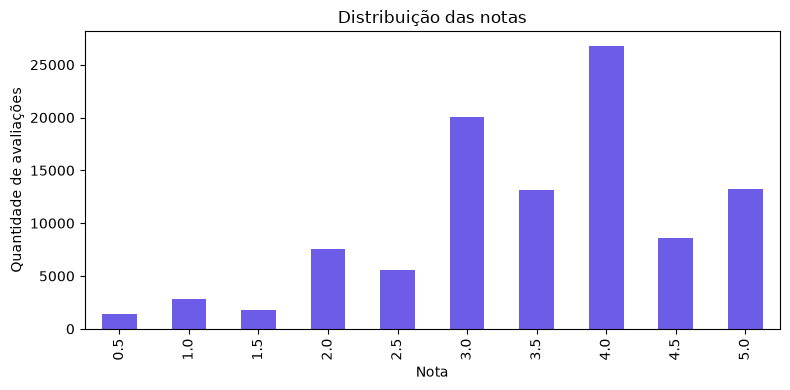

In [9]:
contagem = ratings["rating"].value_counts().sort_index()

contagem.plot(kind="bar", color="#6c5ce7")
plt.title("Distribuição das notas")
plt.xlabel("Nota")
plt.ylabel("Quantidade de avaliações")
plt.tight_layout()
plt.savefig("../docs/distribuicao_notas.png", dpi=150)
plt.show()

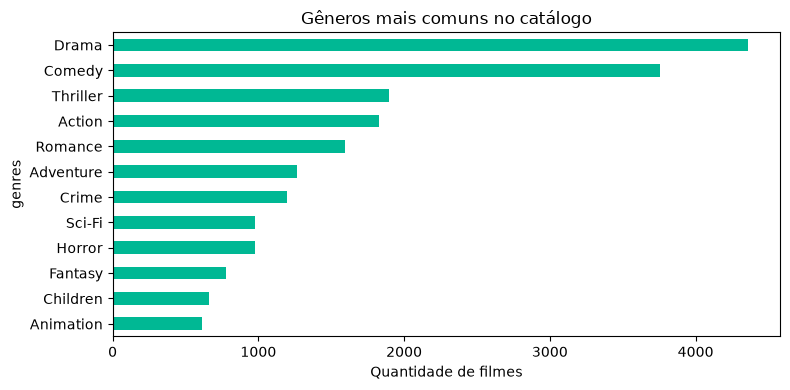

In [10]:
generos = movies["genres"].str.split("|").explode()
top_generos = generos.value_counts().head(12)

top_generos.sort_values().plot(kind="barh", color="#00b894")
plt.title("Gêneros mais comuns no catálogo")
plt.xlabel("Quantidade de filmes")
plt.tight_layout()
plt.savefig("../docs/generos_mais_comuns.png", dpi=150)
plt.show()

In [11]:
stats = ratings.groupby("movieId").agg(
    n_avaliacoes=("rating", "count"),
    nota_media=("rating", "mean"),
).reset_index()

stats = stats.merge(movies[["movieId", "title"]], on="movieId")

stats.sort_values("n_avaliacoes", ascending=False).head(10)

,movieId,n_avaliacoes,nota_media,title
314,356,329,4.164134,Forrest Gump (1994)
277,318,317,4.429022,"Shawshank Redemption, The (1994)"
257,296,307,4.197068,Pulp Fiction (1994)
510,593,279,4.161290,"Silence of the Lambs, The (1991)"
1938,2571,278,4.192446,"Matrix, The (1999)"
224,260,251,4.231076,Star Wars: Episode IV - A New Hope (1977)
418,480,238,3.750000,Jurassic Park (1993)
97,110,237,4.031646,Braveheart (1995)
507,589,224,3.970982,Terminator 2: Judgment Day (1991)
461,527,220,4.225000,Schindler's List (1993)


In [12]:
stats.sort_values("nota_media", ascending=False).head(10)

,movieId,n_avaliacoes,nota_media,title
9693,187717,1,5.0,Won't You Be My Neighbor? (2018)
4667,6983,1,5.0,Jane Eyre (1944)
3802,5328,1,5.0,Rain (2001)
7927,95843,1,5.0,Goodbye Charlie (1964)
2934,3941,1,5.0,Sorority House Massacre (1986)
2933,3940,1,5.0,Slumber Party Massacre III (1990)
2932,3939,1,5.0,Slumber Party Massacre II (1987)
5015,7815,1,5.0,True Stories (1986)
9349,162414,1,5.0,Moonlight
9347,162344,1,5.0,Tom Segura: Mostly Stories (2016)


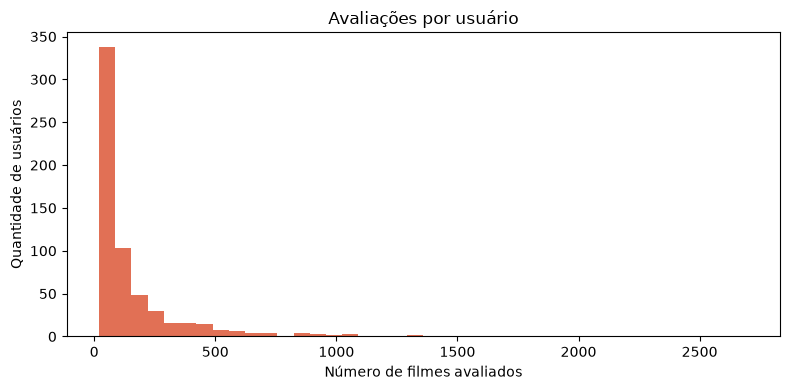

Mínimo: 20
Mediana: 70.5
Máximo: 2698


In [13]:
por_usuario = ratings.groupby("userId")["rating"].count()

por_usuario.plot(kind="hist", bins=40, color="#e17055")
plt.title("Avaliações por usuário")
plt.xlabel("Número de filmes avaliados")
plt.ylabel("Quantidade de usuários")
plt.tight_layout()
plt.savefig("../docs/avaliacoes_por_usuario.png", dpi=150)
plt.show()

print("Mínimo:", por_usuario.min())
print("Mediana:", por_usuario.median())
print("Máximo:", por_usuario.max())

In [14]:
n_usuarios = ratings["userId"].nunique()
n_filmes = ratings["movieId"].nunique()
possiveis = n_usuarios * n_filmes
esparsidade = 1 - len(ratings) / possiveis

print(f"Células possíveis: {possiveis:,}")
print(f"Avaliações existentes: {len(ratings):,}")
print(f"Esparsidade: {esparsidade:.2%}")

Células possíveis: 5,931,640
Avaliações existentes: 100,836
Esparsidade: 98.30%
